1. Сформулировать постановку задачу, которую хочется решать в рамках курса.

Задача - предсказание оттока клиентов банка.

Бизнес-постановка задачи:
Банку важно заранее понимать, какие клиенты с высокой вероятностью перестанут пользоваться услугами банка. Это позволяет вовремя запускать удерживающие меры, чтобы повысить retention.

ML-постановка задачи:
Задача бинарной классификации:
1 - клиент уйдет из банка
0 - клиент останется

Набор данных:
Датасет из ABC Multistate bank, потому что он содержит целевую переменную - факт ухода клиента (churn), включает числовые и категориальные признаки, позволяет провести содержательный EDA.


2. Ключевая метрика - Recall:

Recall для класса оттока, потому что для банка особенна критична ошибка, при который модель не распознает клиента, который собирается уйти (FN). В этом случае банк не предпримет никаких действий для удержания клиента и его потеряет.
Метрика Accuracy не подходит в качестве ключевой, потому что присутствует дисбаланс классов: клиентов, которые остаются, обычно существенно больше, чем клиентов, которые уходят. В такой ситуации модель может показать высокую accuracy, даже если плохо находит отток.

Дополнительная метрика - F1-score:

F1-score, потому что она позволяет учитывать баланс между precision и recall, чтобы модель не начала помечать слишком много клиентов как уходящих.


3. EDA / предварительный разведочный анализ:


Загрузим датасет и выведем:
1. Первые пять сторк
2. Размер датасета
3. Название столбцов
4. Информацию о данных
5. Пропуски
6. Количество дубликатов
7. Базовые статистики по числовым признакам
8. Базовые статистики по категориальным признакам

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("Bank Customer Churn Prediction.csv")

print("\nПервые пять строк датасета:")

display(df.head())

print("\nРазмер датасета:", df.shape)

print("\nСтолбцы:", df.columns.tolist())

print( "\nИнформация о датасете:")

display(df.info())

print("\nКоличество пропусков:")

display(df.isnull().sum())

print("\nКоличество дубликатов", df.duplicated().sum())

print("\nБазовые статистики по числовым признакам:")
display(df.describe().T)

print("\nБазовые статистики по категориальным признакам:")
display(df.describe(include='object').T)


Первые пять строк датасета:


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Размер датасета: (10000, 12)

Столбцы: ['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: f

None


Количество пропусков:


,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0



Количество дубликатов 0

Базовые статистики по числовым признакам:


,count,mean,std,min,25%,50%,75%,max
customer_id,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
credit_score,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
products_number,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
credit_card,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
active_member,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
estimated_salary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48
churn,10000.0,2.037000e-01,0.402769,0.00,0.00,0.000000e+00,0.000000e+00,1.00



Базовые статистики по категориальным признакам:


,count,unique,top,freq
country,10000,3,France,5014
gender,10000,2,Male,5457


Анализ ключевой переменной Churn по распределению

In [ ]:
target = "churn"

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title('Распределение целевой переменной (churn)')
plt.xlabel('Churn')
plt.ylabel('Количество клиентов')
plt.show()

print('\nРаспределение классов:')
display(df[target].value_counts())

print('\nРаспределение классов в долях:')
display((df[target].value_counts(normalize=True) * 100).round(2))


Анализ категориальных признаков


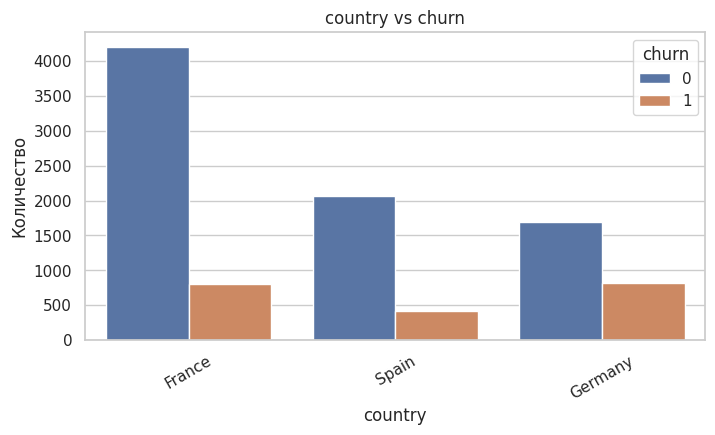


Доля оттока по country (%):


,churn
country,
Germany,32.44
Spain,16.67
France,16.15


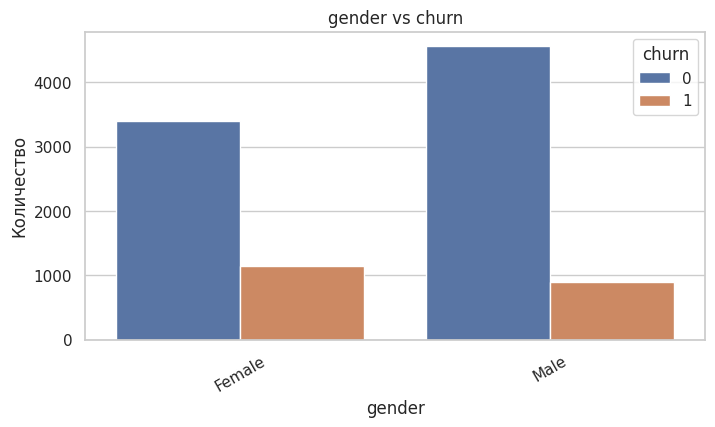


Доля оттока по gender (%):


,churn
gender,
Female,25.07
Male,16.46


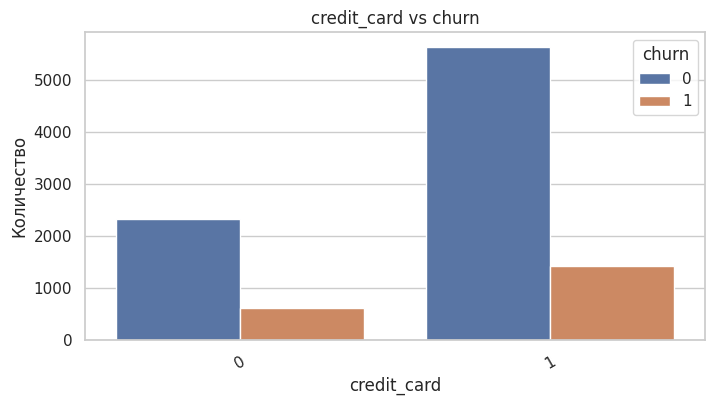


Доля оттока по credit_card (%):


,churn
credit_card,
0,20.81
1,20.18


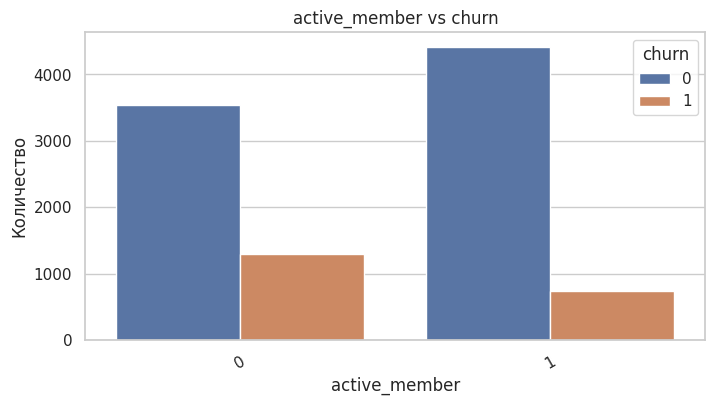


Доля оттока по active_member (%):


,churn
active_member,
0,26.85
1,14.27


In [26]:
cat_cols = ['country', 'gender', 'credit_card', 'active_member']

for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue=target)
    plt.title(f'{col} vs churn')
    plt.xlabel(col)
    plt.ylabel('Количество')
    plt.xticks(rotation=30)
    plt.legend(title='churn')
    plt.show()

    churn_rate = (
        df.groupby(col)[target]
        .mean()
        .sort_values(ascending=False)
        .mul(100)
        .round(2)
    )
    print(f'\nДоля оттока по {col} (%):')
    display(churn_rate)


Для анализа числовых признаков приведены гистограммы для демонстрации распределения числовых признаков, boxplot для каждого числового признака и отдельно для churn.

In [ ]:
num_cols = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'products_number',
    'estimated_salary'
]

df[num_cols].hist(figsize=(16, 10), bins=30)
plt.suptitle('Распределения числовых признаков', fontsize=16)
plt.tight_layout()
plt.show()

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot для {col}')
    plt.xlabel(col)
    plt.show()

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x=target, y=col)
    plt.title(f'{col} по классам churn')
    plt.xlabel('churn')
    plt.ylabel(col)
    plt.show()


Провел анализ плотности распределения,

Корреляционный анализ (матрица),

Определил среднее значения признаков по классам,

Составлена таблица сопряженности для категориальных признаков,

Провел поиск выборосов через IQR.

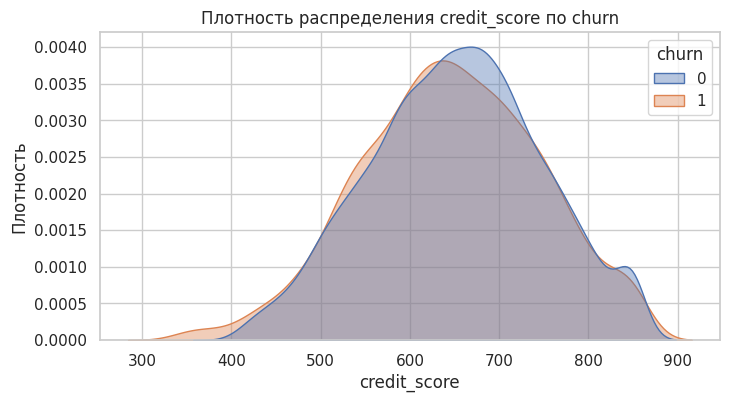

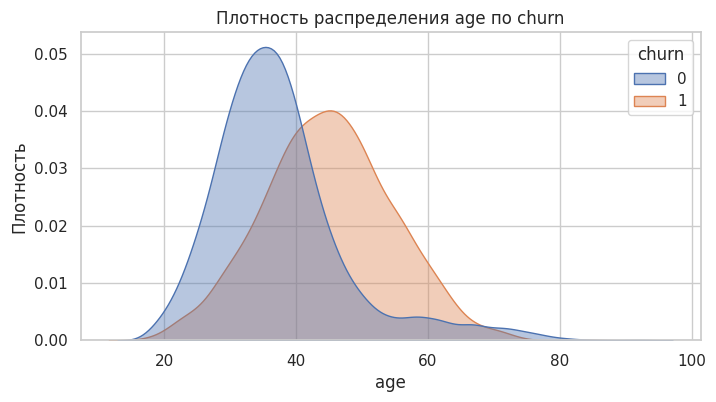

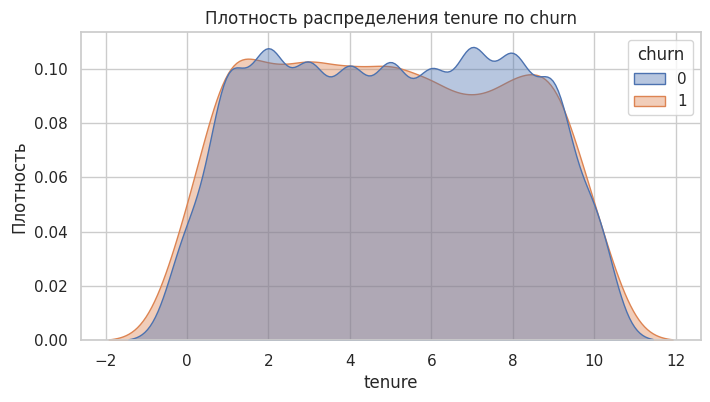

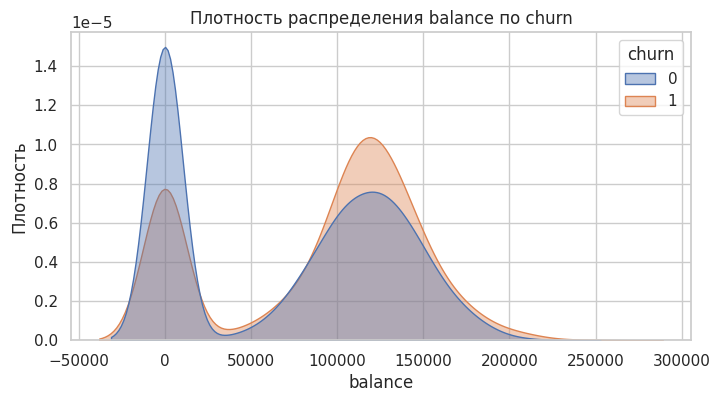

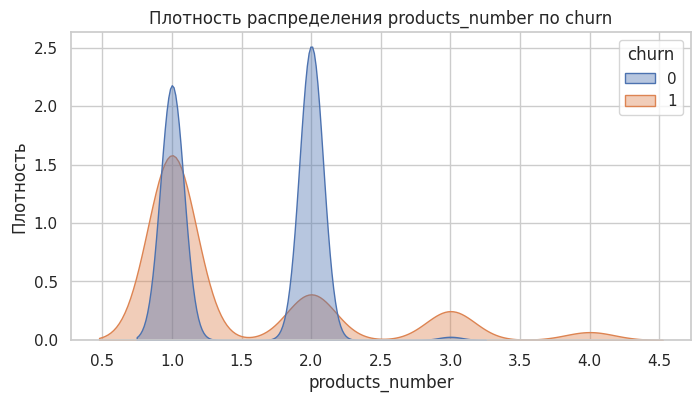

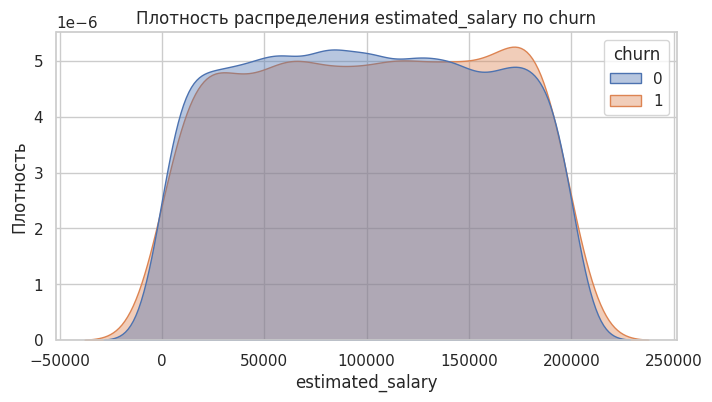

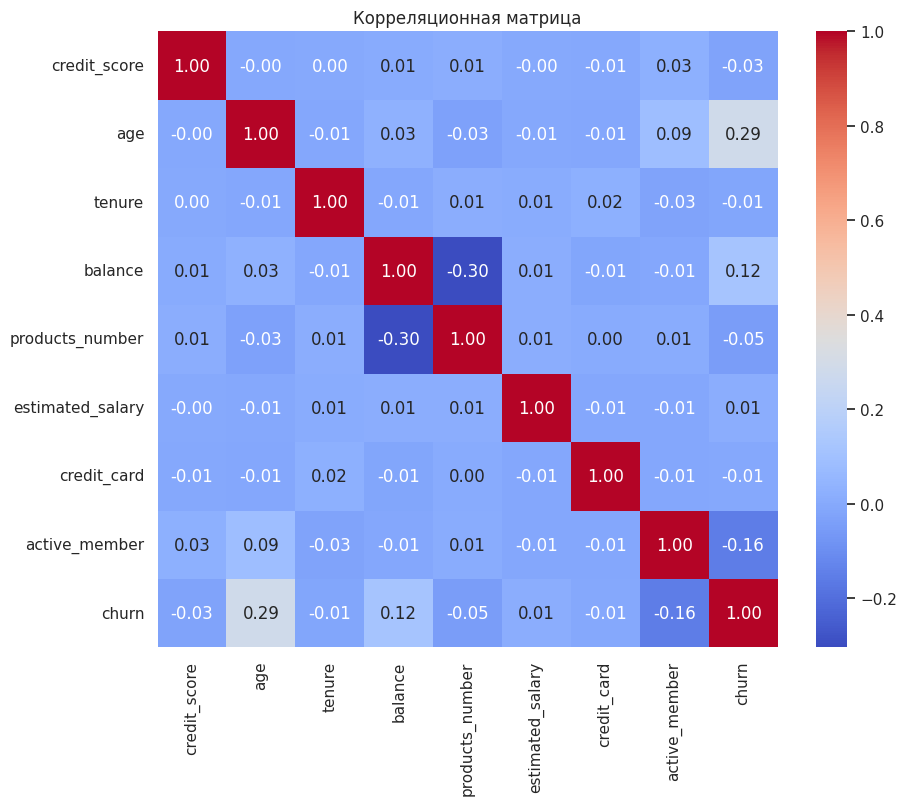


Средние значения числовых признаков по классам:


,Stayed (0),Churned (1),Difference
balance,72745.296779,91108.539337,18363.242558
estimated_salary,99738.391772,101465.677531,1727.285759
age,37.408389,44.837997,7.429608
products_number,1.544267,1.475209,-0.069059
tenure,5.033279,4.932744,-0.100535
credit_score,651.853196,645.351497,-6.501699



Таблица сопряженности для country:


churn,0,1,All
country,,,
France,4204,810,5014
Germany,1695,814,2509
Spain,2064,413,2477
All,7963,2037,10000



Нормализованная таблица для country:


churn,0,1
country,,
France,0.838,0.162
Germany,0.676,0.324
Spain,0.833,0.167


... (10 outputs left out)


Нормализованная таблица для active_member:


churn,0,1
active_member,,
0,0.731,0.269
1,0.857,0.143



Сводка по выбросам:


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outliers_count,outliers_percent
1,age,32.00,44.0000,12.0000,14.00000,62.00000,359,3.59
4,products_number,1.00,2.0000,1.0000,-0.50000,3.50000,60,0.60
0,credit_score,584.00,718.0000,134.0000,383.00000,919.00000,15,0.15
2,tenure,3.00,7.0000,4.0000,-3.00000,13.00000,0,0.00
3,balance,0.00,127644.2400,127644.2400,-191466.36000,319110.60000,0,0.00
5,estimated_salary,51002.11,149388.2475,98386.1375,-96577.09625,296967.45375,0,0.00


In [25]:
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.kdeplot(data=df, x=col, hue=target, fill=True, common_norm=False, alpha=0.4)
    plt.title(f'Плотность распределения {col} по churn')
    plt.xlabel(col)
    plt.ylabel('Плотность')
    plt.show()

plt.figure(figsize=(10, 8))
corr = df[num_cols + ['credit_card', 'active_member', 'churn']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляционная матрица')
plt.show()

grouped_stats = df.groupby(target)[num_cols].mean().T
grouped_stats.columns = ['Stayed (0)', 'Churned (1)']
grouped_stats['Difference'] = grouped_stats['Churned (1)'] - grouped_stats['Stayed (0)']

print('\nСредние значения числовых признаков по классам:')
display(grouped_stats.sort_values(by='Difference', ascending=False))

for col in cat_cols:
    print(f'\nТаблица сопряженности для {col}:')
    display(pd.crosstab(df[col], df[target], margins=True))

    print(f'\nНормализованная таблица для {col}:')
    display(pd.crosstab(df[col], df[target], normalize='index').round(3))

outlier_summary = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]

    outlier_summary.append({
        'feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outliers_count': outliers_count,
        'outliers_percent': round(outliers_count / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values(by='outliers_percent', ascending=False)

print("\nСводка по выбросам:")
display(outlier_df)

Выводы по EDA:
1. В датасете отсутствуют пропуски, что упрощает дальнейшую предобработку.
2. Целевая переменная churn может быть несбалансированной, поэтому accuracy не стоит использовать как основную метрику.
3. Категориальные признаки country, gender и active_member потенциально связаны с вероятностью оттока.
4. Среди числовых признаков наибольший интерес представляют age, balance, products_number и credit_score.
5. В данных могут присутствовать выбросы, которые следует учитывать при построении моделей.